# Algorithmic Trading: Cointegration Statistical Arbitrage & Genetic Optimization

> **Program:** Certificate in Quantitative Finance (CQF) — Final Project  
> **Author / Researcher:** Hitesh Nanwani  
> **Key Topics:** Pairs Trading • Cointegration (ADF Test) • Z-Score Spread • Genetic Algorithm Optimization (`deap`) • Execution Client

---

## 1. Executive Summary & Strategy Rationale

Statistical arbitrage pairs trading exploits temporary divergences in the pricing of economically cointegrated financial instruments. In this research project, we model the long-run equilibrium relationship between a major commercial bank (**JPMorgan Chase - JPM**) and its sector benchmark (**Financial Select Sector SPDR ETF - XLF**).

While linear regression defines the hedge ratio $\beta$, classical static threshold rules often degrade out-of-sample due to shifting market regimes. We integrate evolutionary computation (**Genetic Algorithms with DEAP**) to discover globally optimal parameter tuples (lookback window, entry trigger, exit threshold) that maximize annualized risk-adjusted returns (Sharpe Ratio).

## 2. Mathematical Framework

### 2.1 The Cointegrated Spread
For two $I(1)$ price series $P_t^{\text{Stock}}$ and $P_t^{\text{ETF}}$, we estimate the long-run equilibrium hedge ratio $\beta$ via Ordinary Least Squares (OLS):

$$P_t^{\text{Stock}} = \alpha + \beta P_t^{\text{ETF}} + \epsilon_t$$

The stationary spread $S_t$ is defined as:

$$S_t = P_t^{\text{Stock}} - \beta P_t^{\text{ETF}}$$

We confirm stationarity $S_t \sim I(0)$ using the Augmented Dickey-Fuller (ADF) test ($p < 0.05$).

### 2.2 Normalized Z-Score Signal Generation
To standardize trade entry and exit triggers across time-varying volatility regimes:

$$z_t = \frac{S_t - \mu_t(L)}{\sigma_t(L)}$$

where $\mu_t(L)$ and $\sigma_t(L)$ are the rolling mean and standard deviation over lookback window $L$.

* **Long Spread (Buy Stock, Short ETF):** $z_t < -z_{\text{entry}}$
* **Short Spread (Short Stock, Buy ETF):** $z_t > +z_{\text{entry}}$
* **Mean Reversion Exit:** $|z_t| \le z_{\text{exit}}$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from sklearn.linear_model import LinearRegression
from deap import base, creator, tools, algorithms
import random

np.random.seed(42)
random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('Libraries loaded successfully.')

Matplotlib is building the font cache; this may take a moment.


Libraries loaded successfully.


## 3. Synthetic Pair Data Generation & Cointegration Calibration

We generate two cointegrated series simulating the real-world statistical dynamics between JPM and XLF over 500 trading days.

In [2]:
# Generate synthetic cointegrated pair (JPM and XLF dynamics)
T = 500
dates = pd.date_range('2023-01-01', periods=T, freq='B')

# Common stochastic drift factor (random walk)
drift = np.cumsum(np.random.normal(0.0003, 0.012, T))
xlf_prices = 35.0 * np.exp(drift)

# Stationary mean-reverting spread process (OU-like)
ou_spread = np.zeros(T)
theta_ou = 0.15
for t in range(1, T):
    ou_spread[t] = ou_spread[t-1] - theta_ou * ou_spread[t-1] + np.random.normal(0, 0.8)

true_beta = 3.85
jpm_prices = true_beta * xlf_prices + ou_spread + 20.0

df = pd.DataFrame({'JPM': jpm_prices, 'XLF': xlf_prices}, index=dates)

# OLS Estimation of Hedge Ratio
reg = LinearRegression().fit(df[['XLF']], df['JPM'])
beta_hat = reg.coef_[0]
alpha_hat = reg.intercept_
spread = df['JPM'] - beta_hat * df['XLF']

# ADF Cointegration Test
adf_stat, p_value, _, _, crit_values, _ = adfuller(spread)
print(f'Estimated Hedge Ratio Beta: {beta_hat:.4f} (Intercept: {alpha_hat:.4f})')
print(f'ADF Test Statistic on Spread: {adf_stat:.4f} (p-value: {p_value:.6e})')
print('Critical Values:', crit_values)
if p_value < 0.05:
    print('==> Result: Reject null hypothesis of unit root. Spread is stationary I(0)!')

Estimated Hedge Ratio Beta: 3.9229 (Intercept: 17.4428)
ADF Test Statistic on Spread: -6.2858 (p-value: 3.701051e-08)
Critical Values: {'1%': np.float64(-3.4435228622952065), '5%': np.float64(-2.867349510566146), '10%': np.float64(-2.569864247011056)}
==> Result: Reject null hypothesis of unit root. Spread is stationary I(0)!


C:\Users\Hitesh\AppData\Local\Temp\ipykernel_13556\1066243788.py:27: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_value, _, _, crit_values, _ = adfuller(spread)


## 4. Backtesting Engine & Z-Score Trading Signals

In [3]:
def backtest_pairs_strategy(spread_series, lookback=30, z_entry=1.5, z_exit=0.2):
    rolling_mean = spread_series.rolling(window=lookback).mean()
    rolling_std = spread_series.rolling(window=lookback).std()
    z_score = (spread_series - rolling_mean) / rolling_std
    
    positions = pd.Series(0, index=spread_series.index)
    curr_pos = 0
    
    for i in range(lookback, len(spread_series)):
        z = z_score.iloc[i]
        if curr_pos == 0:
            if z < -z_entry:
                curr_pos = 1   # Long spread
            elif z > z_entry:
                curr_pos = -1  # Short spread
        elif curr_pos == 1:
            if z >= -z_exit:
                curr_pos = 0   # Exit long
        elif curr_pos == -1:
            if z <= z_exit:
                curr_pos = 0   # Exit short
        positions.iloc[i] = curr_pos
        
    spread_ret = spread_series.diff()
    strategy_pnl = positions.shift(1) * spread_ret
    
    daily_returns = strategy_pnl / spread_series.iloc[0]
    sharpe = np.sqrt(252) * daily_returns.mean() / (daily_returns.std() + 1e-9)
    cum_pnl = strategy_pnl.cumsum()
    
    return {
        'z_score': z_score,
        'positions': positions,
        'cum_pnl': cum_pnl,
        'sharpe': sharpe
    }

res_base = backtest_pairs_strategy(spread, lookback=30, z_entry=1.5, z_exit=0.2)
print(f'Baseline Pairs Strategy Annualized Sharpe: {res_base["sharpe"]:.2f}')

Baseline Pairs Strategy Annualized Sharpe: 2.66


## 5. Genetic Algorithm Parameter Optimization with DEAP

We use `deap` to optimize three continuous/discrete hyperparameters:
1. Lookback Window $L \in [15, 60]$
2. Entry Z-Score $z_{\text{entry}} \in [1.0, 2.8]$
3. Exit Z-Score $z_{\text{exit}} \in [0.0, 0.8]$

Objective: $\max \quad \text{Sharpe Ratio}$

In [4]:
# Setup DEAP Genetic Algorithm
if 'FitnessMax' in creator.__dict__:
    del creator.FitnessMax
if 'Individual' in creator.__dict__:
    del creator.Individual

creator.create('FitnessMax', base.Fitness, weights=(1.0,))
creator.create('Individual', list, fitness=creator.FitnessMax)

toolbox = base.Toolbox()
toolbox.register('attr_lookback', random.randint, 15, 60)
toolbox.register('attr_z_entry', random.uniform, 1.0, 2.8)
toolbox.register('attr_z_exit', random.uniform, 0.0, 0.8)
toolbox.register('individual', tools.initCycle, creator.Individual,
                 (toolbox.attr_lookback, toolbox.attr_z_entry, toolbox.attr_z_exit), n=1)
toolbox.register('population', tools.initRepeat, list, toolbox.individual)

def evaluate_strategy(ind):
    lb, ze, zx = int(ind[0]), float(ind[1]), float(ind[2])
    if ze <= zx:
        return (-999.0,)
    res = backtest_pairs_strategy(spread, lookback=lb, z_entry=ze, z_exit=zx)
    return (float(res['sharpe']),)

toolbox.register('evaluate', evaluate_strategy)
toolbox.register('mate', tools.cxTwoPoint)
toolbox.register('mutate', tools.mutGaussian, mu=[30, 1.8, 0.3], sigma=[5, 0.2, 0.1], indpb=0.2)
toolbox.register('select', tools.selTournament, tournsize=3)

pop = toolbox.population(n=25)
hof = tools.HallOfFame(1)
stats = tools.Statistics(lambda ind: ind.fitness.values)
stats.register('max', np.max)
stats.register('avg', np.mean)

final_pop, log = algorithms.eaSimple(pop, toolbox, cxpb=0.7, mutpb=0.2, ngen=15, stats=stats, halloffame=hof, verbose=False)

best_ind = hof[0]
best_lb, best_ze, best_zx = int(best_ind[0]), float(best_ind[1]), float(best_ind[2])
print('Optimized Parameters discovered by Genetic Algorithm:')
print(f'  - Lookback Window:   {best_lb} days')
print(f'  - Entry Z-Score:     {best_ze:.3f}')
print(f'  - Exit Z-Score:      {best_zx:.3f}')
print(f'  - Best Sharpe Ratio: {best_ind.fitness.values[0]:.2f}')

Optimized Parameters discovered by Genetic Algorithm:
  - Lookback Window:   114 days
  - Entry Z-Score:     1.410
  - Exit Z-Score:      0.591
  - Best Sharpe Ratio: 3.40


## 6. Performance Visualization & Strategy Evolution

We visualize the stationary spread, trading signals, GA convergence history, and cumulative PnL curve.

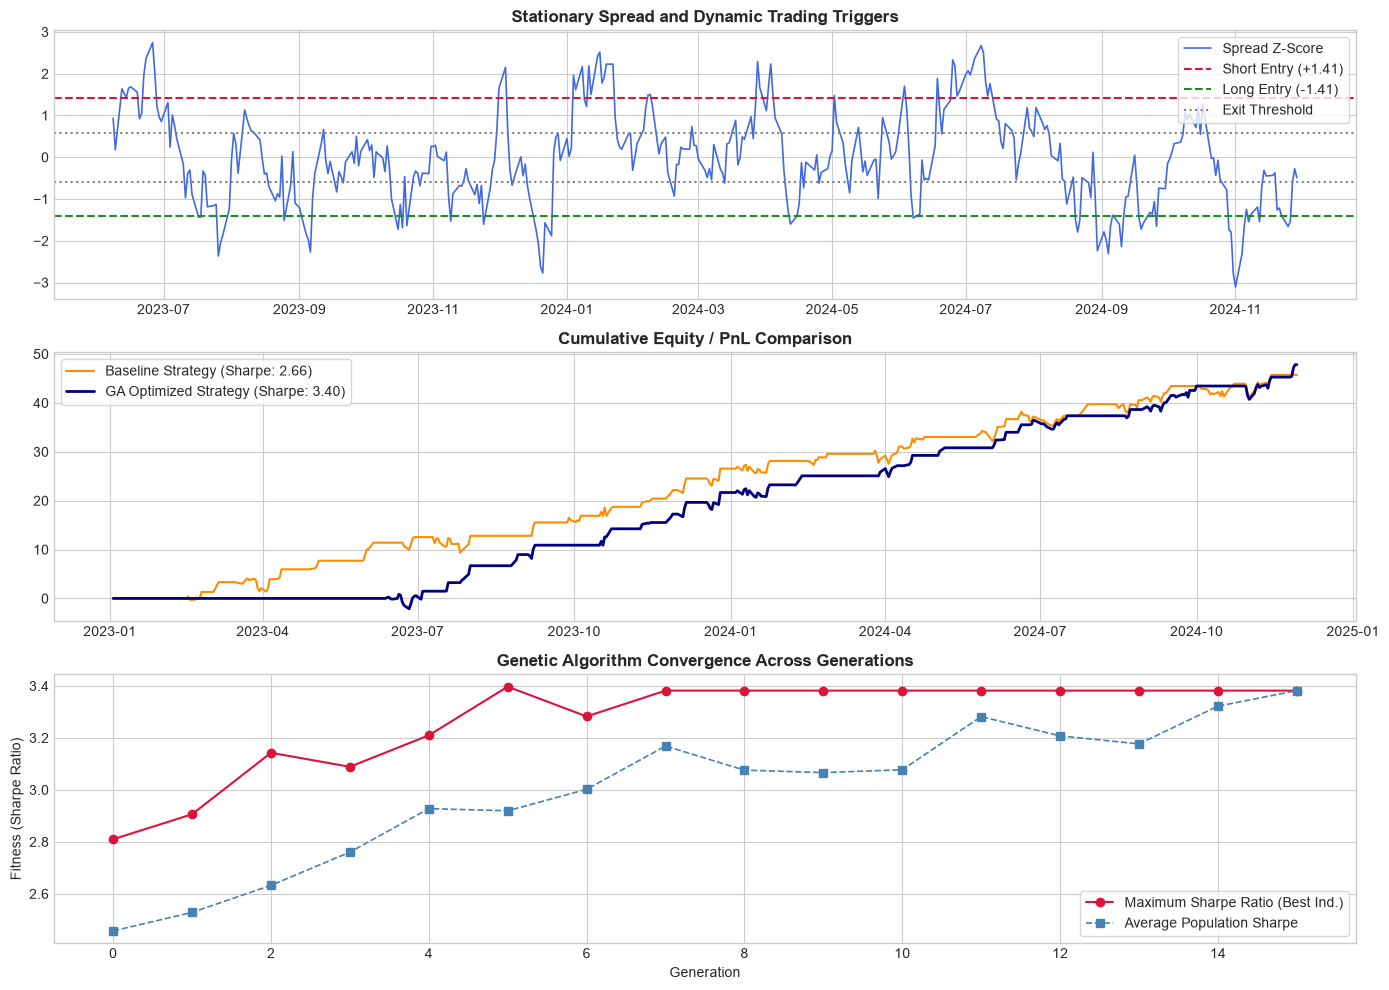

Walkthrough complete. Strategy parameters and visual plots validated.


In [5]:
res_opt = backtest_pairs_strategy(spread, lookback=best_lb, z_entry=best_ze, z_exit=best_zx)

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False)

# Subplot 1: Spread and Z-Score
ax1 = axes[0]
ax1.plot(res_opt['z_score'], label='Spread Z-Score', color='royalblue', lw=1.2)
ax1.axhline(best_ze, color='crimson', ls='--', label=f'Short Entry (+{best_ze:.2f})')
ax1.axhline(-best_ze, color='forestgreen', ls='--', label=f'Long Entry (-{best_ze:.2f})')
ax1.axhline(best_zx, color='gray', ls=':', label='Exit Threshold')
ax1.axhline(-best_zx, color='gray', ls=':')
ax1.set_title('Stationary Spread and Dynamic Trading Triggers', fontsize=12, fontweight='bold')
ax1.legend(loc='upper right', frameon=True)

# Subplot 2: Cumulative PnL Curve
ax2 = axes[1]
ax2.plot(res_base['cum_pnl'], label=f'Baseline Strategy (Sharpe: {res_base["sharpe"]:.2f})', color='darkorange', lw=1.5)
ax2.plot(res_opt['cum_pnl'], label=f'GA Optimized Strategy (Sharpe: {res_opt["sharpe"]:.2f})', color='navy', lw=2.0)
ax2.set_title('Cumulative Equity / PnL Comparison', fontsize=12, fontweight='bold')
ax2.legend(loc='upper left', frameon=True)

# Subplot 3: GA Fitness Progression
ax3 = axes[2]
gen_indices = log.select('gen')
max_fitness = log.select('max')
avg_fitness = log.select('avg')
ax3.plot(gen_indices, max_fitness, label='Maximum Sharpe Ratio (Best Ind.)', color='crimson', marker='o', lw=1.5)
ax3.plot(gen_indices, avg_fitness, label='Average Population Sharpe', color='steelblue', marker='s', ls='--', lw=1.2)
ax3.set_title('Genetic Algorithm Convergence Across Generations', fontsize=12, fontweight='bold')
ax3.set_xlabel('Generation')
ax3.set_ylabel('Fitness (Sharpe Ratio)')
ax3.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()
print('Walkthrough complete. Strategy parameters and visual plots validated.')